In [1]:
import pandas as pd
from io import BytesIO
from urllib.request import urlopen
from zipfile import ZipFile

URL = ('https://archive.ics.uci.edu/static/public/222/bank+marketing.zip')
outer = ZipFile(BytesIO(urlopen(URL).read()))
inner = ZipFile(BytesIO(outer.read('bank-additional.zip')))
df = pd.read_csv(inner.open('bank-additional/bank-additional.csv'), sep=';')
df.to_csv('bank.csv', sep=';', index=False)
print(df.shape)
df.head()

(4119, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,30,blue-collar,married,basic.9y,no,yes,no,cellular,may,fri,...,2,999,0,nonexistent,-1.8,92.893,-46.2,1.313,5099.1,no
1,39,services,single,high.school,no,no,no,telephone,may,fri,...,4,999,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,no
2,25,services,married,high.school,no,yes,no,telephone,jun,wed,...,1,999,0,nonexistent,1.4,94.465,-41.8,4.962,5228.1,no
3,38,services,married,basic.9y,no,unknown,unknown,telephone,jun,fri,...,3,999,0,nonexistent,1.4,94.465,-41.8,4.959,5228.1,no
4,47,admin.,married,university.degree,no,yes,no,cellular,nov,mon,...,1,999,0,nonexistent,-0.1,93.200,-42.0,4.191,5195.8,no


In [2]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import train_test_split
import pandas as pd

# Encode categorical features
X = pd.get_dummies(df.drop(columns=['y']), drop_first=True)

# Convert target variable to binary (0 and 1)
y = df['y'].map({'yes': 1, 'no': 0})

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

model = GradientBoostingClassifier(
	n_estimators=100,
	learning_rate=0.1,
	max_depth=3,
	random_state=42
)
model.fit(X_train, y_train)
print("Train Accuracy:", round(model.score(X_train, y_train), 2))
print("Test Accuracy:", round(model.score(X_test, y_test), 2))


Train Accuracy: 0.95
Test Accuracy: 0.91


In [3]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV

pipeline = Pipeline([
    ('sc', StandardScaler()),
    ('model', GradientBoostingClassifier(random_state=42))
])

param_grid = {
    'model__n_estimators': [50, 100, 200],
    'model__max_depth': [3, 5, 10],   
    'model__learning_rate': [0.01, 0.1, 0.2]
}

grid = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Best score:", grid.best_score_)
print("Best params:", grid.best_params_)

Best score: 0.9122913505311077
Best params: {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 100}


In [4]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform

pipeline = Pipeline([
    ('sc', StandardScaler()),
    ('model', GradientBoostingClassifier(random_state=42))
])

param_distributions = {
    'model__n_estimators': randint(50, 250),  
    'model__max_depth': randint(1, 6),        
    'model__learning_rate': uniform(0.01, 0.2), 
    'model__subsample': [0.7, 0.8, 0.9, 1.0]
}

random_search = RandomizedSearchCV(
    estimator=pipeline,
    param_distributions=param_distributions,
    n_iter=20,           
    cv=5,   
    scoring='accuracy',
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train, y_train)

print("Eng yaxshi score:", random_search.best_score_)
print("Eng yaxshi parametrlar:", random_search.best_params_)

Eng yaxshi score: 0.9150227617602429
Eng yaxshi parametrlar: {'model__learning_rate': np.float64(0.041198904067240534), 'model__max_depth': 3, 'model__n_estimators': 137, 'model__subsample': 0.7}


In [5]:
from xgboost import XGBClassifier

In [6]:
from sklearn.metrics import (
	accuracy_score,
	precision_score,
	recall_score,
	f1_score,
	roc_auc_score
)

def metrics(X_test, y_test, model):
	y_pred = model.predict(X_test)
	y_proba = model.predict_proba(X_test)[:, 1]
	result = {
		"Accuracy_score": round(accuracy_score(y_test, y_pred), 2),
		"Pecision_score": round(precision_score(y_test, y_pred), 2),
		"Recall_score": round(recall_score(y_test, y_pred), 2),
		"F1-score": round(f1_score(y_test, y_pred), 2),
		"ROC-AUC-score": round(roc_auc_score(y_test, y_proba), 2)
	}
	return pd.DataFrame(result, index=[0])

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

xg = XGBClassifier(
	n_estimators = 200,
	learning_rate = 0.05
)
xg.fit(X_train, y_train)
metrics(X_test, y_test, xg)

,Accuracy_score,Pecision_score,Recall_score,F1-score,ROC-AUC-score
0,0.91,0.62,0.42,0.5,0.94


In [8]:
pipeline = Pipeline([
    ('sc', StandardScaler()),
    ('model', XGBClassifier(random_state=42))
])

param_grid = {
    'model__n_estimators': [50, 100, 200, 500],
    'model__learning_rate': [0.01, 0.1, 0.2, 0.5]
}

grid = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Best score:", grid.best_score_)
print("Best params:", grid.best_params_)

Best score: 0.908649468892261
Best params: {'model__learning_rate': 0.1, 'model__n_estimators': 100}


In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

xg = XGBClassifier(
	max_depth=4,
	min_child_weight=1,
	gamma=0
)
xg.fit(X_train, y_train)
metrics(X_test, y_test, xg)

,Accuracy_score,Pecision_score,Recall_score,F1-score,ROC-AUC-score
0,0.91,0.61,0.48,0.54,0.94


In [10]:
from sklearn.metrics import classification_report
print(classification_report(y_train, xg.predict(X_train)))

              precision    recall  f1-score   support

           0       0.99      1.00      0.99      2934
           1       0.97      0.89      0.93       361

    accuracy                           0.99      3295
   macro avg       0.98      0.94      0.96      3295
weighted avg       0.98      0.99      0.98      3295



In [11]:
xg = XGBClassifier(
	n_estimators=200,
	learning_rate=0.05,
	max_depth=4,
	colsample_bytree=0.8,
	random_state=42
)
xg.fit(X_train, y_train)
metrics(X_test, y_test, xg)

,Accuracy_score,Pecision_score,Recall_score,F1-score,ROC-AUC-score
0,0.92,0.66,0.46,0.54,0.94


In [12]:
print(classification_report(y_train, xg.predict(X_train)))

              precision    recall  f1-score   support

           0       0.96      0.99      0.98      2934
           1       0.89      0.69      0.78       361

    accuracy                           0.96      3295
   macro avg       0.93      0.84      0.88      3295
weighted avg       0.96      0.96      0.95      3295



In [20]:
from xgboost import XGBClassifier

X_train_full, X_test, y_train_full, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_train, X_valid, y_train, y_valid = train_test_split(X_train_full, y_train_full, test_size=0.2, stratify=y_train_full, random_state=42)



modelxgb = XGBClassifier(
	n_estimators = 1000,
	learning_rate=0.05,
	max_depth=4,
	early_stopping_rounds = 20,
	random_state=42
)

modelxgb.fit(X_train, y_train, eval_set=[(X_valid, y_valid)],verbose=True)
print(f"train score: {modelxgb.score(X_train, y_train)}")
metrics(X_valid, y_valid, modelxgb)

[0]	validation_0-logloss:0.32741
[1]	validation_0-logloss:0.31277
[2]	validation_0-logloss:0.30062
[3]	validation_0-logloss:0.28984
[4]	validation_0-logloss:0.28022
[5]	validation_0-logloss:0.27191
[6]	validation_0-logloss:0.26436
[7]	validation_0-logloss:0.25722
[8]	validation_0-logloss:0.25093
[9]	validation_0-logloss:0.24537
[10]	validation_0-logloss:0.24050
[11]	validation_0-logloss:0.23553
[12]	validation_0-logloss:0.23096
[13]	validation_0-logloss:0.22668
[14]	validation_0-logloss:0.22263
[15]	validation_0-logloss:0.21892
[16]	validation_0-logloss:0.21567
[17]	validation_0-logloss:0.21262
[18]	validation_0-logloss:0.20960
[19]	validation_0-logloss:0.20691
[20]	validation_0-logloss:0.20426
[21]	validation_0-logloss:0.20213
[22]	validation_0-logloss:0.19991
[23]	validation_0-logloss:0.19748
[24]	validation_0-logloss:0.19524
[25]	validation_0-logloss:0.19321
[26]	validation_0-logloss:0.19129
[27]	validation_0-logloss:0.18938
[28]	validation_0-logloss:0.18770
[29]	validation_0-loglos

,Accuracy_score,Pecision_score,Recall_score,F1-score,ROC-AUC-score
0,0.93,0.73,0.56,0.63,0.96


In [19]:
print(f"best iteration: {modelxgb.best_iteration}")
print(f"best score: {modelxgb.best_score}")

best iteration: 184
best score: 0.16254470069092988


In [ ]:
from xgboost import XGBClassifier

X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_train, X_valid, y_train, y_valid = train_test_split(X_tmp, y_tmp, test_size=0.2, stratify=y_tmp, random_state=42)

def train(lr, Xtr=X_train, Xva=X_valid, patience=50):
	model = XGBClassifier(n_estimators=2000, learning_rate=lr, max_depth=3, eval_metric="logloss", early_stopping_rounds=patience, random_state=42)
	# validation oxirida - early stopping oxirgi set'ga qaraydi
	model.fit(Xtr, y_train, eval_set = [(Xtr, y_train), (Xva, y_valid)], verbose=False)
	return model

In [30]:
models = {}
for lr in (0.3, 0.05):
	m = train(lr)
	acc = accuracy_score(y_test, m.predict(X_test))
	print(f"lr={lr}: best_iteration={m.best_iteration}, best_score={m.best_score:.4f}, test acc = {acc:.4f}")
	models[lr] = m
model = models[0.05]


lr=0.3: best_iteration=50, best_score=0.1606, test acc = 0.9102
lr=0.05: best_iteration=246, best_score=0.1636, test acc = 0.9090


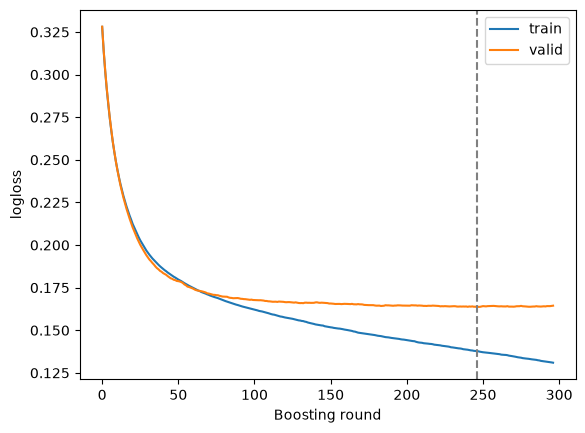

In [34]:
import matplotlib.pyplot as plt
res = model.evals_result()
plt.plot(res["validation_0"]["logloss"], label="train")
plt.plot(res["validation_1"]["logloss"], label="valid")
plt.axvline(model.best_iteration, ls="--", color="gray")
plt.xlabel("Boosting round"); plt.ylabel("logloss"); plt.legend(); plt.show()


In [41]:
importance = model.feature_importances_
importance_df = pd.DataFrame({
	"feature": X_train.columns,
	"importance": model.feature_importances_
}).sort_values(
	"importance",
	ascending=False
)
print(importance_df)

                          feature  importance
9                     nr.employed    0.529726
1                        duration    0.075253
5                    emp.var.rate    0.024259
8                       euribor3m    0.022898
52               poutcome_success    0.021154
6                  cons.price.idx    0.019228
42                      month_mar    0.018632
31                default_unknown    0.017732
3                           pdays    0.017471
37              contact_telephone    0.014469
7                   cons.conf.idx    0.013816
36                       loan_yes    0.012419
18                 job_technician    0.012026
47                day_of_week_mon    0.011774
10                job_blue-collar    0.011231
43                      month_may    0.011092
50                day_of_week_wed    0.010793
22                 marital_single    0.010758
28  education_professional.course    0.009976
0                             age    0.009834
45                      month_oct 

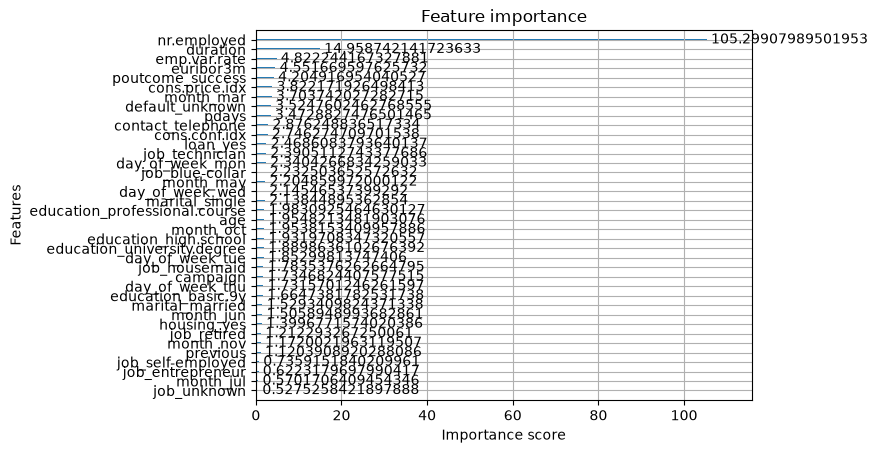

In [45]:
from xgboost import plot_importance

plot_importance(
	model,
	importance_type="gain"
)
plt.show()